# B1. 신호 기초: purity, ploidy, CN 이 정해지면 데이터에 무엇이 보이나

**목표**
- 시퀀싱 데이터에서 PURPLE 이 쓰는 두 신호, **깊이 비(depth ratio)** 와 **BAF** 가 어디서 오는지 그림으로 이해합니다.
- purity, ploidy, CN 이 정해지면 두 신호가 어떻게 정해지는지 식으로 쓰고, 거꾸로 깊이 비에서 CN 을 계산합니다.
- GC 함량이 왜 깊이를 흔드는지, 그것이 왜 "깊게 읽어도 줄지 않는 잡음"이 되는지 봅니다.
- 다음 노트북에서 쓸 가짜 종양 데이터를 만듭니다.

**이 노트북이 답하는 질문**: 종양 세포가 적으면, copy 하나 차이가 데이터에서 얼마나 작아지나?

식은 PURPLE 4.1 소스 코드(hmftools 저장소, 태그 `purple-v4.1`)를 옮긴 `purple_mini.py` 를 함께 씁니다 [2].
문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 공통 스타일 STYLE.md §3-1, 팔레트 Okabe-Ito(색의 뜻 고정)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
import purple_mini as pm

# ---- 공통 그림 스타일 (study_build/purple/_proto_pileup.py 에서 복사, STYLE.md §3-1) ----
# 색은 뜻이 고정: 종양 주황, 정상 하늘, allele A 파랑, allele B 빨강, read 회청, 핵심 메시지 자주, 정답·통과 초록.
# 그 밖의 비교(조건 둘, purity 여러 개)는 진한 회색 계열(GREYS)과 선 모양으로 구분하고 직접 라벨을 단다.
import logging
from matplotlib.patches import FancyBboxPatch

COL = dict(tumour="#E69F00", normal="#56B4E9", alleleA="#0072B2", alleleB="#D55E00",
           read="#8C9BAB", read_rev="#B3BFCC", highlight="#CC79A7", ok="#009E73",
           ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#FFF4E0")
GREYS = ["#111827", "#4B5563", "#8B95A3", "#BCC3CC"]      # 순서 있는 비교용(진한 것 = 첫째)
TUMOUR_LIGHT, NORMAL_LIGHT, BOX = "#FBE3B6", "#CDE8F8", "#F1F3F6"
NEUTRAL = "#E6E9EE"                                      # 종양과 상관없는 강조 띠·상자 (옅은 주황 shade 는 종양 구간에만)
LABEL_BOX = dict(fc="white", ec="none", alpha=0.85, pad=1.5)   # 선이나 점 위에 놓이는 글자 뒤 흰 상자


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title)


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """그림의 핵심 메시지 한 줄(자주색 굵게). 데이터 위에 겹치지 않는 빈 자리에 둔다."""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


apply_theme()


def flow(ax, nodes, edges, fs=9.5):
    """nodes: {key: (x, y, text, fill)}, edges: [(a, b)]. 둥근 상자와 가는 화살표로 개념 지도를 그린다."""
    W, H = 2.7, 1.15
    for x, y, text, col in nodes.values():
        ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.04,rounding_size=0.18",
                                    fc=col, ec="#C4CAD3", lw=0.9, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=COL["ink"], zorder=3)
    for a, b in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        dx, dy = x2 - x1, y2 - y1
        if abs(dx) * H >= abs(dy) * W:
            s = np.sign(dx); start, end = (x1 + s * W / 2, y1 + dy * (W / 2) / abs(dx)), (x2 - s * W / 2, y2 - dy * (W / 2) / abs(dx))
        else:
            s = np.sign(dy); start, end = (x1, y1 + s * H / 2), (x2, y2 - s * H / 2)
        ax.annotate("", xy=end, xytext=start, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", lw=1.0, color=COL["muted"], shrinkA=2, shrinkB=2, mutation_scale=11))
    ax.set_axis_off()


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12, 3.9))
    ax.add_patch(FancyBboxPatch((0.05, 0.1), 6.6, 3.55, boxstyle="round,pad=0,rounding_size=0.25", fc="none",
                                ec=COL["muted"], lw=1.2, ls=(0, (4, 3)), zorder=0))
    nodes = {"bx": (1.5, 3.0, "Tumour biopsy\n(tumour + normal\ncells)", TUMOUR_LIGHT),
             "bl": (1.5, 0.9, "Blood\n(normal cells only)", NORMAL_LIGHT),
             "co": (5.0, 3.0, "COBALT\nreads per 1 kb window\n-> GC-corrected ratio", BOX),
             "am": (5.0, 0.9, "AMBER\nBAF at heterozygous\nSNPs", BOX),
             "pu": (8.5, 1.95, "PURPLE\nfind purity and\nploidy (normFactor)", "white"),
             "cn": (12.0, 1.95, "Copy number per\nsegment\n(major, minor)", "white")}
    flow(ax, nodes, [("bx", "co"), ("bl", "co"), ("bx", "am"), ("bl", "am"), ("co", "pu"), ("am", "pu"), ("pu", "cn")])
    callout(ax, 0.25, 3.82, "B1 = the dashed box: where the depth ratio and BAF come from", va="bottom")
    note(ax, 8.5, 0.55, "B2", ha="center", fontsize=9.5); note(ax, 12.0, 0.55, "B2-B4", ha="center", fontsize=9.5)
    ax.set_xlim(0, 13.5); ax.set_ylim(0, 4.3)
    plt.show()


def pack_rows(starts, length, gap=6):
    """IGV 처럼 겹치지 않게 줄을 배정"""
    row_end, rows = [], []
    for s in starts:
        for i, e in enumerate(row_end):
            if s > e + gap:
                row_end[i] = s + length; rows.append(i); break
        else:
            row_end.append(s + length); rows.append(len(row_end) - 1)
    return np.array(rows)


def draw_reads_and_depth(seed=3, n_reads=40, length=600, read_len=150):
    rng = np.random.default_rng(seed)
    starts = np.sort(rng.integers(-read_len + 1, length, size=n_reads))
    rows = pack_rows(starts, read_len)
    fig, ax = plt.subplots(2, 1, figsize=(10.5, 5.0), sharex=True, gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.35})
    for s, r in zip(starts, rows):
        ax[0].add_patch(FancyBboxPatch((s, r + 0.12), read_len, 0.62, boxstyle="round,pad=0,rounding_size=0.3", lw=0, color=COL["read"]))
    ax[0].set_ylim(rows.max() + 1.2, -0.4); ax[0].set_yticks([]); ax[0].spines["left"].set_visible(False)
    ax[0].tick_params(axis="x", length=0)
    panel(ax[0], "A", f"{n_reads} reads of {read_len} bp land at random places on a {length} bp stretch")
    pos = np.arange(0, length)
    depth = ((starts[None, :] <= pos[:, None]) & (pos[:, None] < starts[None, :] + read_len)).sum(1)
    ax[1].fill_between(pos, depth, step="mid", color=COL["read"], alpha=0.35, lw=0)
    ax[1].plot(pos, depth, color=COL["read"], lw=0.8, drawstyle="steps-mid")
    ax[1].axhline(depth.mean(), ls=(0, (4, 2)), color=COL["ink"], lw=1.4)
    callout(ax[1], length - 8, depth.max() * 1.5, f"dashed line = mean depth {depth.mean():.1f}x: each base is covered by about {depth.mean():.0f} reads",
            ha="right", va="top", fontsize=9.5)
    ax[1].set_xlim(0, length); ax[1].set_ylim(0, depth.max() * 1.55); ygrid(ax[1])
    ax[1].set_ylabel("depth"); ax[1].set_xlabel("position (bp)")
    panel(ax[1], "B", "Depth = number of reads covering each position")
    plt.show()


def draw_cells(purity=0.6, n=10):
    n_t = int(round(purity * n))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.1))
    for ax, letter, (title, kinds) in zip(axes, "AB", [(f"Tumour biopsy: {n_t} tumour + {n - n_t} normal cells", ["T"] * n_t + ["N"] * (n - n_t)),
                                                      ("Blood (matched normal): normal cells only", ["N"] * n)]):
        for i, k in enumerate(kinds):
            x, y = i % 5, 1 - i // 5
            ax.add_patch(Circle((x, y), 0.38, fc=COL["tumour"] if k == "T" else COL["normal"], ec="white", lw=2))
            ax.text(x, y, k, ha="center", va="center", fontsize=11, weight="bold", color="white")
        ax.set_xlim(-0.6, 4.6); ax.set_ylim(-0.75, 1.6); ax.set_aspect("equal"); ax.set_axis_off()
        panel(ax, letter, title)
    callout(axes[0], 2.0, -0.62, f"purity = tumour cells / all cells = {n_t}/{n} = {n_t / n:.1f}", ha="center", va="top")
    plt.show()


def _chrom(ax, x, y, allele, w=1.1, h=0.22):
    col = COL["alleleA"] if allele == "A" else COL["alleleB"]
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.1", fc=col, ec="none"))
    ax.text(x, y, allele, ha="center", va="center", color="white", fontsize=9, weight="bold")


def draw_cn_states():
    states = [("normal", "AB"), ("gain", "AAB"), ("loss (LOH)", "A"), ("copy-neutral LOH", "AA"), ("genome doubling", "AABB")]
    fig = plt.figure(figsize=(12, 5.1))
    top = fig.add_gridspec(2, 5, height_ratios=[1.3, 1], hspace=0.2)
    for j, (name, al) in enumerate(states):
        ax = fig.add_subplot(top[0, j])
        ax.add_patch(FancyBboxPatch((-0.95, -0.2), 1.9, 1.75, boxstyle="round,pad=0.02,rounding_size=0.3", fc=BOX, ec="none"))
        for i, a in enumerate(al):
            _chrom(ax, 0, 1.3 - i * 0.33, a)
        nA, nB = al.count("A"), al.count("B")
        ax.text(0, -0.45, f"{name}\nCN {nA + nB} = major {max(nA, nB)} + minor {min(nA, nB)}", ha="center", va="top", fontsize=9.5, color=COL["ink"])
        ax.set_xlim(-1.1, 1.1); ax.set_ylim(-0.95, 1.65); ax.set_axis_off()
        if j == 0:
            panel(ax, "A", "Allele states (blue = allele A from one parent, red = allele B from the other)")
            ax.title.set_position((0, 1.0))
    ax = fig.add_subplot(top[1, :])
    seg_len = np.array([30, 15, 25, 10, 20])
    seg_cn = np.array([2, 3, 4, 1, 3])
    edges = np.concatenate([[0], np.cumsum(seg_len)])
    for s, e, c in zip(edges[:-1], edges[1:], seg_cn):
        ax.plot([s + 0.4, e - 0.4], [c, c], color=COL["tumour"], lw=5, solid_capstyle="round")
        ax.text((s + e) / 2, c + 0.28, f"CN {c}", ha="center", fontsize=9.5, color=COL["ink"])
    psi = np.average(seg_cn, weights=seg_len)
    ax.axhline(psi, ls=(0, (4, 2)), color=COL["ink"], lw=1.2)
    callout(ax, edges[-1] + 2, psi + 0.12, f"ploidy = average CN = {psi:.2f}", va="bottom")
    note(ax, edges[-1] + 2, psi - 0.12, "(toy: weighted by length)", va="top")
    ax.set_xlim(0, edges[-1] + 32); ax.set_ylim(0, 5); ygrid(ax)
    ax.set_xlabel("genome position (toy units)"); ax.set_ylabel("tumour CN")
    panel(ax, "B", "A toy tumour genome: one CN per segment")
    plt.show()


def draw_norm_factor(p=0.6, cns=(2, 4, 2, 4, 3, 3)):
    """견본 그림(study_build/example_normfactor.png)을 공통 스타일로 다시 그린 것."""
    cns = np.array(cns)
    tumour, normal = p * cns, np.full(len(cns), 2 * (1 - p))
    dna = tumour + normal
    ratio = dna / dna.mean()
    psi = cns.mean()
    nf = 2 / (2 - 2 * p + psi * p)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.7, 1.25, 1.3], "wspace": 0.33})
    x = np.arange(len(cns))
    ax[0].bar(x, normal, color=COL["normal"], width=0.72)
    ax[0].bar(x, tumour, bottom=normal, color=COL["tumour"], width=0.72)
    ax[0].text(-0.5, dna.max() * 1.38, "tumour cells: p x CN", va="top", fontsize=9, color=COL["tumour"], weight="semibold")
    ax[0].text(-0.5, dna.max() * 1.28, "normal cells: 2 x (1 - p)", va="top", fontsize=9, color=COL["normal"], weight="semibold")
    note(ax[0], -0.5, dna.max() * 1.18, "above bars: CN and depth ratio", va="top", fontsize=8.5)
    ax[0].axhline(dna.mean(), ls=(0, (4, 2)), color=COL["ink"], lw=1.2)
    note(ax[0], len(cns) - 0.45, dna.mean() + 0.08, f"genome\naverage\n= {dna.mean():.1f}", ha="left", va="bottom", color=COL["ink"])
    note(ax[0], len(cns) - 0.45, dna.mean() - 0.08, "normalised\nto ratio\n~1.0", ha="left", va="top", color=COL["ink"])
    ax[0].set_xlim(-0.6, len(cns) + 0.95)
    for i, (c, r) in enumerate(zip(cns, ratio)):
        ax[0].text(i, dna[i] + 0.06, f"CN {c}\n{r:.2f}", ha="center", va="bottom", fontsize=8.5, color=COL["ink"])
    ax[0].set_xticks(x, [str(i + 1) for i in x]); ax[0].set_xlabel("segment"); ax[0].set_ylim(0, dna.max() * 1.42); ygrid(ax[0])
    ax[0].set_ylabel("DNA amount (copies per cell)")
    panel(ax[0], "A", f"What COBALT sees (purity {p}, ploidy {psi:.1f})")
    for j, (ps, lab) in zip([0, 1.35], [(2.0, "tumour ploidy 2"), (psi, f"tumour ploidy {psi:.1f}")]):
        n = 2 / (2 - 2 * p + ps * p)
        ticks = n * (1 - p + p * np.arange(0, 6) / 2)
        ax[1].vlines(j, 0.3, 1.9, color=COL["muted"], lw=1)
        for k, t in enumerate(ticks):
            col = COL["highlight"] if k == 2 else COL["ink"]
            ax[1].hlines(t, j - 0.12, j + 0.12, color=col, lw=2.4 if k == 2 else 1)
            ax[1].text(j + 0.16, t, f"CN {k}", va="center", fontsize=9, color=col, weight="semibold" if k == 2 else "normal",
                       bbox=dict(facecolor="white", edgecolor="none", pad=0.5), zorder=3)
        ax[1].text(j, 0.2, f"{lab.replace('tumour ', '')}\nnormFactor {n:.2f}", ha="center", va="top", fontsize=9, color=COL["ink"])
    ax[1].axhline(1.0, ls=(0, (4, 2)), color=COL["muted"], lw=1, zorder=1)
    note(ax[1], -0.58, 1.05, "ratio 1.0", va="bottom", bbox=LABEL_BOX)
    ax[1].set_xlim(-0.6, 2.75); ax[1].set_ylim(0.0, 1.95); ax[1].set_xticks([]); ax[1].spines["bottom"].set_visible(False)
    ax[1].set_ylabel("depth ratio")
    panel(ax[1], "B", "normFactor = ratio where CN 2 sits")
    ax[1].annotate("CN 2 sits\nat the\nnormFactor", xy=(1.74, 2 / (2 - 2 * p + psi * p)), xytext=(2.1, 1.32),
                   ha="left", va="center", fontsize=9.5, color=COL["highlight"], fontweight="semibold",
                   arrowprops=dict(arrowstyle="-|>", color=COL["highlight"], lw=1.1, shrinkA=4, shrinkB=4))
    to_cn = lambda r, n: 2 + 2 * (r - n) / (p * n)
    good, bad = to_cn(ratio, nf), to_cn(ratio, 1.0)
    for k in range(1, 6):
        ax[2].axhline(k, color=COL["grid"], lw=1, zorder=0)
    ax[2].scatter(x, bad, s=52, color="#A7AFBA", marker="s", zorder=3, lw=0)
    ax[2].scatter(x, good, s=62, color=COL["ok"], zorder=4, lw=0)
    note(ax[2], x[-1] + 0.25, good[-1], f"normFactor {nf:.2f}\n(correct)", color=COL["ok"], va="center", fontsize=9)
    note(ax[2], x[-1] + 0.25, bad[-1], "normFactor 1.00\n(wrong)", color=COL["muted"], va="center", fontsize=9)
    ax[2].set_xticks(x, [str(i + 1) for i in x]); ax[2].set_xlabel("segment"); ax[2].set_ylabel("calculated CN"); ax[2].set_ylim(0.5, 5.4)
    ax[2].set_xlim(-0.5, len(cns) + 1.2)
    panel(ax[2], "C", "Right normFactor -> whole-number CN")
    plt.show()


def toy_gc_track(n=3000, seed=7):
    """1 kb 창 n 개. GC 는 수십~수백 kb 덩어리 + 창마다 작은 흔들림."""
    rng = np.random.default_rng(seed)
    gc, i = np.empty(n), 0
    while i < n:
        L = int(rng.integers(30, 200)); gc[i:i + L] = rng.normal(0.41, 0.045); i += L
    return np.clip(gc + rng.normal(0, 0.012, n), 0.25, 0.65)


def gc_yield(gc, centre=0.44, width=0.10):
    """GC 에 따른 read 수율(가장 좋은 GC 에서 1). 모양만 흉내 낸 장난감 곡선."""
    return np.exp(-0.5 * ((gc - centre) / width) ** 2)


def simulate_gc_depth(depth=60, purity=0.6, seed=7, hidden_sd=0.008):
    """한 줄 유전체(3 Mb, COBALT 처럼 1 kb 창): 진짜 CN 2, 가운데 300 kb 만 CN 3.
    read 수율은 창의 GC 가 아니라 '조각(fragment)의 GC' 를 따른다고 두고, 조각 GC 에는 창 GC 로는 안 보이는 흔들림을 섞는다."""
    rng = np.random.default_rng(seed)
    gc = toy_gc_track(seed=seed)
    n = len(gc)
    cn = np.full(n, 2.0); cn[1300:1600] = 3
    hidden = np.convolve(rng.normal(0, 1, n + 100), np.ones(100) / np.sqrt(100), "valid")[:n] * hidden_sd
    rel = pm.relative_dna(purity, cn)
    lam = depth * 1000 / 150                          # 1 kb 창 하나의 평균 read 수
    rng = np.random.default_rng(seed + depth)         # 같은 유전체, 깊이마다 다른 read 뽑기
    counts = rng.poisson(lam * rel / rel.mean() * gc_yield(gc + hidden))
    raw = counts / counts.mean()
    bucket = np.round(gc, 2)                          # GC 를 0.01 단위 버킷으로
    med = pd.Series(counts).groupby(bucket).transform("median").to_numpy()
    corrected = counts / med
    corrected = corrected / corrected.mean()
    expected = rel / rel.mean()
    return dict(gc=gc, cn=cn, raw=raw, corrected=corrected, expected=expected, counts=counts)


def draw_gc_sequence(seed=2):
    rng = np.random.default_rng(seed)
    def seq(gc_frac, n=48):
        k = int(round(gc_frac * n)); s = np.array(list("GC" * n))[:k].tolist() + np.array(list("AT" * n))[:n - k].tolist()
        rng.shuffle(s); return s
    fig, ax = plt.subplots(figsize=(12, 2.3))
    for row, (lab, frac) in enumerate([("AT-rich window", 0.29), ("GC-rich window", 0.63)]):
        s = seq(frac)
        for i, b in enumerate(s):
            gcb = b in "GC"
            ax.text(i * 0.21, -row * 0.9, b, ha="center", va="center", family="monospace", fontsize=11.5,
                    color=COL["ink"] if gcb else "#B8BFC8", weight="bold" if gcb else "normal")
        k = sum(b in "GC" for b in s)
        ax.text(len(s) * 0.21 + 0.3, -row * 0.9, f"{lab}:  GC = {k}/{len(s)} = {k / len(s):.2f}", va="center", fontsize=10.5, color=COL["ink"])
    callout(ax, -0.3, 0.75, "GC content = (G + C) / all bases   (G and C in bold, A and T in grey)", va="bottom")
    ax.set_xlim(-0.3, 16.2); ax.set_ylim(-1.5, 1.2); ax.set_axis_off()
    plt.show()


def draw_gc_bias(depth=60):
    s = simulate_gc_depth(depth=depth)
    x = np.arange(len(s["gc"])) / 1000          # Mb
    fig = plt.figure(figsize=(13, 7.4))
    gs = fig.add_gridspec(3, 2, width_ratios=[1, 2.8], hspace=0.62, wspace=0.22)
    a = fig.add_subplot(gs[:, 0])
    g = np.linspace(0.15, 0.75, 200)
    a.axvspan(0.2, 0.6, color=NEUTRAL, lw=0)
    a.plot(g, gc_yield(g), color=COL["ink"], lw=1.8)
    note(a, 0.4, 0.05, "windows kept\nby COBALT v2.0\n(GC 0.2-0.6)", ha="center", color=COL["ink"])
    a.set_xlabel("GC content of DNA fragment"); a.set_ylabel("relative number of reads"); ygrid(a)
    panel(a, "A", "Toy GC curve:\nboth ends lose reads")
    b = fig.add_subplot(gs[0, 1]); b.plot(x, s["gc"], color=COL["ink"], lw=0.7)
    b.set_ylabel("GC"); ygrid(b); b.tick_params(axis="x", length=0)
    panel(b, "B", "GC content changes in blocks along the genome (toy 3 Mb, 1 kb windows)")
    c = fig.add_subplot(gs[1, 1], sharex=b)
    c.plot(x, s["raw"], ".", ms=1.6, color=COL["read"], alpha=0.8, rasterized=True)
    c.plot(x, s["expected"], color=COL["ink"], lw=1.6)
    note(c, 1.62, 1.33, "true CN 3", color=COL["ink"], fontsize=9.5, bbox=LABEL_BOX); note(c, 2.85, 1.05, "true CN 2", color=COL["ink"], fontsize=9.5, va="bottom", bbox=LABEL_BOX)
    c.set_ylabel("ratio"); c.set_ylim(0.3, 1.7); ygrid(c); c.tick_params(axis="x", length=0)
    panel(c, "C", "Raw depth: waves follow GC and look like copy-number changes")
    d = fig.add_subplot(gs[2, 1], sharex=b)
    d.plot(x, s["corrected"], ".", ms=1.6, color=COL["read"], alpha=0.8, rasterized=True)
    d.plot(x, s["expected"], color=COL["ink"], lw=1.6)
    callout(d, 1.68, 1.42, "after GC correction only the real gain stands out", va="bottom", fontsize=9.5)
    d.set_ylabel("ratio"); d.set_ylim(0.3, 1.7); d.set_xlabel("position (Mb)"); ygrid(d)
    panel(d, "D", "GC-corrected (each window / median of same-GC windows)")
    plt.show()
    return s


def draw_depth_vs_wave():
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True, gridspec_kw={"wspace": 0.08})
    rows = []
    for ax, letter, depth in zip(axes, "AB", [30, 120]):
        s = simulate_gc_depth(depth=depth)
        x = np.arange(len(s["gc"])) / 1000
        resid = s["corrected"] / s["expected"] - 1
        smooth = pd.Series(resid).rolling(40, center=True, min_periods=1).mean().to_numpy()
        ax.plot(x, resid, ".", ms=1.6, color=COL["read"], alpha=0.65, rasterized=True)
        ax.plot(x, smooth, color=COL["ink"], lw=1.6)
        ax.axhline(0, color=COL["muted"], lw=0.8); ygrid(ax)
        panel(ax, letter, f"depth {depth}x"); ax.set_xlabel("position (Mb)")
        rows.append(dict(depth=depth, total_sd=resid.std(), slow_wave_sd=smooth.std(), fast_speckle_sd=(resid - smooth).std()))
    note(axes[0], 0.05, -0.36, "dots: each 1 kb window", fontsize=9.5, bbox=LABEL_BOX)
    note(axes[0], 0.05, -0.43, "black line: slow wave (40 kb average)", color=COL["ink"], fontsize=9.5, bbox=LABEL_BOX)
    callout(axes[1], 2.95, 0.3, "4x deeper: the dots tighten, the slow wave stays", ha="right", va="top", bbox=LABEL_BOX)
    axes[0].set_ylabel("ratio error after\nGC correction")
    plt.show()
    return pd.DataFrame(rows).round(3)


def draw_snp_pileup(p=0.6, n=20, seed=1):
    rng = np.random.default_rng(seed)
    b_major = pm.expected_baf(p, 1, 0)                 # LOH 구간, 남은 allele = A
    k_b = int(round((1 - b_major) * n))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for ax, letter, (title, nb) in zip(axes, "AB", [("Blood at a heterozygous SNP (A/G)", n // 2),
                                                   (f"Tumour biopsy, LOH region (major 1, minor 0), purity {p}", k_b)]):
        alle = np.array(["G"] * nb + ["A"] * (n - nb)); rng.shuffle(alle)
        for i, a in enumerate(alle):
            s = rng.integers(-55, -5)
            ax.add_patch(FancyBboxPatch((s, i + 0.12), 60, 0.62, boxstyle="round,pad=0,rounding_size=0.3", lw=0, color="#D9DEE5"))
            ax.text(0, i + 0.43, a, ha="center", va="center", fontsize=9, weight="bold",
                    color=COL["alleleB"] if a == "G" else COL["alleleA"])
        ax.axvline(0, color=COL["muted"], lw=0.6, ls=":")
        raw = nb / n
        ax.text(0, n + 0.9, f"B allele (G) = {nb}/{n} = {raw:.2f}   ->   folded BAF = {0.5 + abs(raw - 0.5):.2f}",
                ha="center", va="bottom", fontsize=9.5, color=COL["ink"])
        ax.set_xlim(-60, 60); ax.set_ylim(n + 4.6, -0.6); ax.set_axis_off()
        panel(ax, letter, title)
    callout(axes[1], 0, n + 2.6, "fewer red G reads: the B allele was lost in tumour cells", ha="center", va="top", fontsize=9.5)
    plt.show()


def draw_folding(p=0.6, depth=60, n=4000, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9), sharey=False, gridspec_kw={"wspace": 0.28})
    bins = np.linspace(0, 1, 51)
    b21 = pm.expected_baf(p, 2, 1)
    phase = rng.random(n) < 0.5
    d = rng.poisson(depth, n); d = d[d > 0]
    raw21 = rng.binomial(d, np.where(phase[:len(d)], b21, 1 - b21)) / d
    axes[0].hist(raw21, bins=bins, color=COL["read"])
    for v in (1 - b21, b21):
        axes[0].axvline(v, color=COL["ink"], lw=1.0)
    panel(axes[0], "A", f"Gain (2,1), raw BAF:\nexpected {1 - b21:.2f} and {b21:.2f} (lines)")
    axes[1].hist(0.5 + np.abs(raw21 - 0.5), bins=bins, color=COL["read"])
    panel(axes[1], "B", "Same sites, folded:\n0.5 + |BAF - 0.5|")
    raw11 = rng.binomial(d, 0.5) / d
    fold11 = 0.5 + np.abs(raw11 - 0.5)
    axes[2].hist(fold11, bins=bins, color="#BCC3CC")
    med = np.median(fold11)
    axes[2].axvline(med, color=COL["muted"], lw=1.2)
    thr = pm.ambiguous_baf(depth)
    axes[2].axvline(thr, color=COL["ink"], ls=(0, (4, 2)), lw=1.4)
    top = axes[2].get_ylim()[1]
    note(axes[2], med - 0.004, top * 0.55, f"median\n{med:.3f}", ha="right", va="top", bbox=LABEL_BOX)
    note(axes[2], thr + 0.004, top * 0.95, f"ambiguity\nthreshold\n{thr:.3f}", color=COL["ink"], va="top")
    callout(axes[2], 0.795, top * 0.55, "balanced sites\nland above 0.5\nafter folding", ha="right", va="top", fontsize=9.5)
    panel(axes[2], "C", "Balanced (1,1), folded (zoom 0.45-0.80)")
    for ax in axes:
        ax.set_xlabel("BAF"); ax.set_xlim(0, 1); ygrid(ax)
    axes[2].set_xlim(0.45, 0.8)
    axes[0].set_ylabel("number of SNP sites")
    plt.show()
    return float(np.mean(fold11 > thr))


def draw_noise_to_cn(noise=0.03):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharey=True, gridspec_kw={"wspace": 0.08})
    cn = np.linspace(0, 5, 101)
    for ax, letter, p in zip(axes, "AB", [0.8, 0.2]):
        nf = pm.norm_factor(p, 2.0)
        r2 = pm.ratio_from_cn(2, p, nf)
        lo, hi = r2 * (1 - noise), r2 * (1 + noise)
        c_lo, c_hi = pm.cn_from_ratio(lo, p, nf), pm.cn_from_ratio(hi, p, nf)
        ax.axhspan(lo, hi, color=COL["read"], alpha=0.35, lw=0)
        ax.axvspan(c_lo, c_hi, color=COL["highlight"], alpha=0.22, lw=0)
        for k in range(6):
            ax.axvline(k, color=COL["grid"], lw=0.8, zorder=0)
        ax.plot(cn, pm.ratio_from_cn(cn, p, nf), color=COL["ink"], lw=1.8)
        panel(ax, letter, f"purity {p}")
        callout(ax, 0.15, 1.82, f"ratio +/-{noise:.0%}  ->  CN {c_lo:.2f} to {c_hi:.2f}", va="top", fontsize=9.5, bbox=LABEL_BOX)
        ax.set_xlabel("tumour CN"); ax.set_ylim(0.3, 1.9); ax.set_xlim(0, 5)
    note(axes[0], 4.9, 0.36, "grey band: ratio noise\npink band: resulting CN range", ha="right", va="bottom")
    axes[0].set_ylabel("depth ratio")
    plt.show()


def draw_nrpcc(depth=60, purities=(0.8, 0.2)):
    fig, ax = plt.subplots(figsize=(11.5, 3.0))
    for row, p in enumerate(purities):
        rel = pm.relative_dna(p, 2)
        per_tumour = depth * p / rel; per_normal = depth * (1 - p) / rel
        left = 0
        for k in range(2):
            ax.barh(row, per_tumour, left=left, color=COL["tumour"], ec="white", lw=1.5, height=0.62)
            ax.text(left + per_tumour / 2, row, f"{per_tumour:.0f}", ha="center", va="center", fontsize=9.5, color="white", weight="bold")
            left += per_tumour
        for k in range(2):
            ax.barh(row, per_normal, left=left, color=COL["normal"], ec="white", lw=1.5, height=0.62)
            ax.text(left + per_normal / 2, row, f"{per_normal:.0f}", ha="center", va="center", fontsize=9.5, color="white", weight="bold")
            left += per_normal
        ax.text(left + 1, row, f"NRPCC = {pm.nrpcc(depth, p, 2):.0f}", va="center", fontsize=10, color=COL["ink"])
    ax.set_yticks(range(len(purities)), [f"purity {p}" for p in purities]); ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.set_xlim(0, depth + 52); ax.set_ylim(len(purities) - 0.45, -0.6)
    ax.set_xlabel(f"{depth} reads at a CN-2 site, split by where they came from")
    panel(ax, "", "Orange = reads from each tumour copy, sky blue = reads from each normal copy")
    p_lo = purities[-1]
    callout(ax, depth + 16, len(purities) - 1, f"<- each tumour copy gets only {pm.nrpcc(depth, p_lo, 2):.0f} reads", va="center", fontsize=9.5)
    plt.show()


def draw_ratio_lines():
    """purity 가 낮을수록 깊이 비-CN 선이 눕는다(7-1)."""
    fig, ax = plt.subplots(figsize=(6.4, 4.3))
    cn = np.linspace(0, 6, 61)
    for i, p in enumerate([0.9, 0.6, 0.3, 0.15]):
        y = pm.ratio_from_cn(cn, p, pm.norm_factor(p, 2.0))
        ax.plot(cn, y, color=GREYS[i], lw=2)
        ax.text(6.1, y[-1], f"purity {p}", va="center", fontsize=9.5, color=GREYS[min(i, 2)])
    ax.set_xlim(0, 7.4); ax.set_xticks(range(7)); ygrid(ax)
    ax.set_xlabel("tumour copy number"); ax.set_ylabel("depth ratio (ploidy 2)")
    panel(ax, "", "Lower purity flattens the ratio-CN line")
    callout(ax, 0.1, ax.get_ylim()[1] * 0.97, "one copy moves the ratio\nby about purity / 2", va="top")
    plt.show()


def draw_baf_convergence(depth=60):
    """purity 가 낮을수록 모든 상태의 BAF 가 0.5 로 모인다(7-3)."""
    states = [(1, 0), (2, 0), (3, 1), (2, 1), (2, 2), (1, 1)]
    purity = np.linspace(0.05, 1, 96)
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    shades = {(1, 0): GREYS[0], (2, 0): GREYS[1], (3, 1): GREYS[2], (2, 1): GREYS[2], (2, 2): GREYS[3], (1, 1): GREYS[3]}
    for M, m in states:
        ax.plot(purity, pm.expected_baf(purity, M, m), color=shades[(M, m)], lw=1.9 if (M, m) != (2, 0) else 2.3,
                ls="-" if (M, m) != (2, 0) else (0, (1, 1.6)))
    thr = pm.ambiguous_baf(depth)
    ax.axhline(thr, color=COL["ink"], ls=(0, (4, 2)), lw=1.2)
    note(ax, 0.98, thr - 0.008, f"ambiguity threshold (depth {depth})", color=COL["ink"], va="top", ha="right")
    labels = {1.0: "(1,0), (2,0)", pm.expected_baf(1, 3, 1): "(3,1)", pm.expected_baf(1, 2, 1): "(2,1)", 0.5: "(1,1) and (2,2)"}
    for yv, lab in labels.items():
        ax.text(1.02, yv, lab, va="center", fontsize=9, color=COL["ink"])
    ax.annotate("(2,0), dotted", (0.45, pm.expected_baf(0.45, 2, 0)), xytext=(-6, 9), textcoords="offset points",
                ha="right", fontsize=9, color=COL["ink"])
    ax.annotate("(1,0), solid", (0.8, pm.expected_baf(0.8, 1, 0)), xytext=(8, -3), textcoords="offset points",
                ha="left", va="top", fontsize=9, color=COL["ink"])
    ax.set_xlim(0, 1.32); ax.set_xticks(np.linspace(0, 1, 6)); ygrid(ax)
    ax.set_xlabel("purity"); ax.set_ylabel("expected BAF (major allele)")
    panel(ax, "", "Expected BAF of each (major, minor) state")
    callout(ax, 0.06, 0.97, "as purity falls, every state\nconverges to 0.5", va="top")
    plt.show()


def draw_sim_two_purities(sims):
    """같은 가짜 종양을 purity 0.7 과 0.2 로(8절)."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 5.6), sharex=True, gridspec_kw={"hspace": 0.42, "wspace": 0.16})
    for row, (p, (bins, bafs)) in enumerate(sims.items()):
        x = np.arange(len(bins))
        axes[row, 0].plot(x, bins.ratio, ".", ms=0.8, color=COL["read"], rasterized=True)
        sub = bafs.sample(30000, random_state=0)
        offset = bins.groupby("chromosome", sort=False).size().cumsum().shift(fill_value=0)
        bx = offset[sub.chromosome].to_numpy() + sub.bin.to_numpy()
        axes[row, 1].plot(bx, sub.baf, ".", ms=0.8, color=COL["read"], alpha=0.5, rasterized=True)
        axes[row, 0].set_ylim(0, 2.5); axes[row, 1].set_ylim(0.45, 1.0)
        axes[row, 0].set_ylabel("depth ratio"); axes[row, 1].set_ylabel("folded BAF")
        panel(axes[row, 0], "AC"[row], f"purity {p}: depth ratio"); panel(axes[row, 1], "BD"[row], f"purity {p}: folded BAF")
        for a in axes[row]:
            ygrid(a)
    callout(axes[1, 0], len(sims[list(sims)[1]][0]) * 0.98, 2.42, "same tumour: the steps are now\nas small as the noise", ha="right", va="top", fontsize=9.5)
    for ax in axes[1]:
        ax.set_xlabel("genome position (100 kb bins, chr1 to chr22)")
    plt.show()

## 개념 지도

PURPLE 은 시료 두 개(종양 조직, 혈액)를 받아 두 가지 신호를 만들고, 그 신호로 purity 와 ploidy 를 맞춘 뒤 구간마다 CN 을 정합니다 [1][5].
이 노트북은 그림의 **왼쪽 절반**, 즉 깊이 비와 BAF 가 어디서 오는지를 다룹니다. 맞추기(오른쪽)는 B2 에서 봅니다.

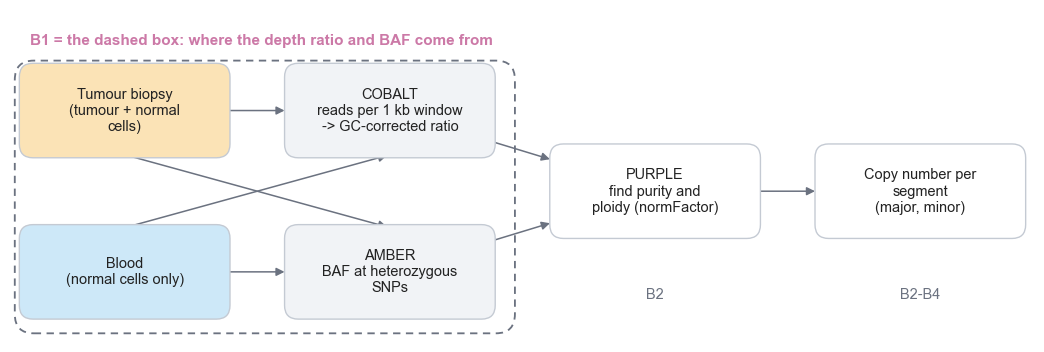

In [2]:
draw_concept_map()

## 먼저 알아 둘 것

아래 여섯 개념은 이 노트북 전체에서 씁니다. 하나씩 그림과 숫자로 봅니다.

### 1. read 와 깊이(depth) — 자세한 내용은 B0

**한 줄 정의**: read 는 시퀀서가 읽은 DNA 조각 한 개의 염기 서열이고, 깊이는 **유전체의 한 자리를 덮는 read 의 개수**입니다.

**왜 필요한가**: 어떤 자리에 DNA copy 가 많으면 그 자리에서 나온 조각도 많아 read 가 더 쌓입니다. 그래서 깊이를 세면 copy 수를 거꾸로 짐작할 수 있고, PURPLE 의 깊이 비는 이 생각에서 출발합니다.

read 가 어떻게 만들어지고(조각, library, paired-end, FASTQ), 어떻게 쌓이며(정렬, MAPQ, pileup), 왜 쌓인 높이가 copy 수를 세는지(깊이 비, BAF 세기, SV 단서)는
**B0 노트북(`lab00_reads-to-copies.ipynb`)** 에 그림과 함께 자세히 있습니다. 여기서는 B1 에 필요한 요점만 다시 봅니다.

실제 예: Hartwig 의 전이암 코호트는 종양을 중앙값 106x, 혈액을 중앙값 38x 로 읽었습니다 [5].

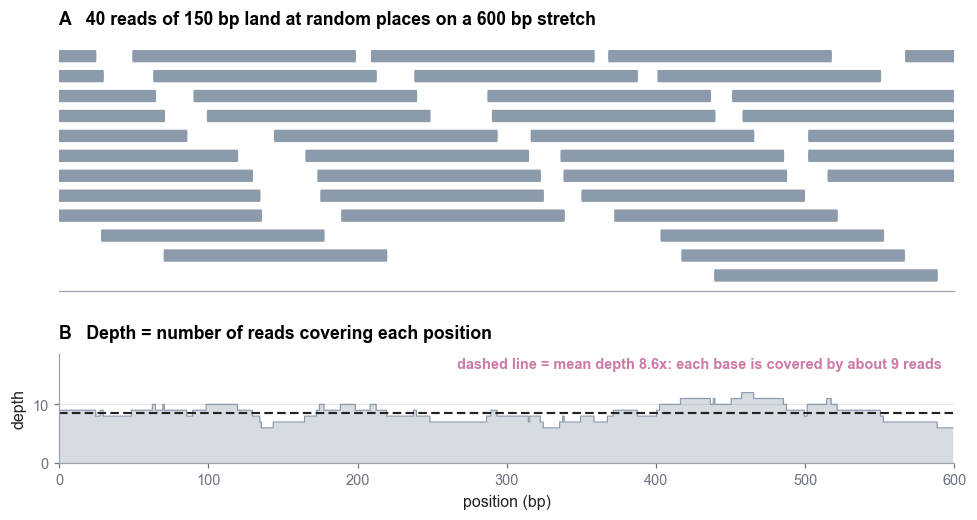

In [3]:
draw_reads_and_depth()

**그림에서 볼 것**
- 위: read(회청색 막대)가 무작위 자리에서 시작합니다. 같은 자리를 여러 read 가 겹쳐 덮습니다.
- 아래: 자리마다 겹친 read 수가 깊이입니다. 평균은 일정해도 자리마다 들쭉날쭉합니다. 이 들쭉날쭉함이 **세기 잡음**(read 를 몇 개 뽑느냐의 우연)입니다.

**직접 바꿔 보기**: `n_reads` 를 160 으로 늘려 보세요. 평균 깊이가 4 배가 되고, 들쭉날쭉함은 평균에 비해 작아집니다.

In [4]:
# draw_reads_and_depth(n_reads=160)

### 2. 종양·정상 짝 시료와 purity

**한 줄 정의**: purity 는 종양 조직 시료에 든 세포 가운데 **종양 세포의 비율**입니다 [1].

**왜 필요한가**: 조직을 떼어 내면 종양 세포 사이에 정상 세포(혈관, 면역세포, 기질 세포)가 섞입니다.
그래서 종양 시료의 read 는 종양 세포와 정상 세포에서 함께 나옵니다. 같은 환자의 **혈액**(정상 세포만)을 함께 읽어 두면,
그 사람의 원래 유전체가 무엇인지 알 수 있어 종양에서 바뀐 것만 골라낼 수 있습니다 [5].

**숫자로 따라가기**: 세포 10 개 중 6 개가 종양 세포면 purity 0.6 입니다. 이 시료에서 나온 DNA 의 일부만 종양 몫입니다.
정확한 비율은 CN 에 따라 달라지는데, 3절에서 계산합니다.

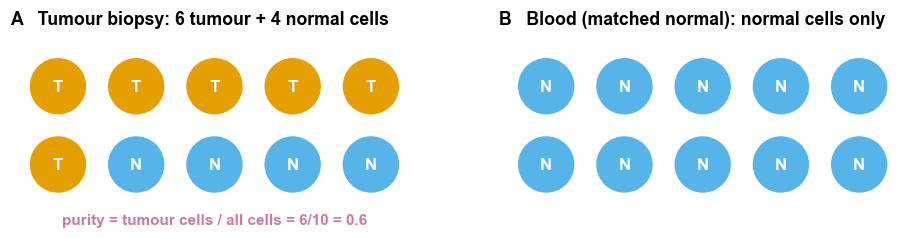

In [5]:
draw_cells(purity=0.6)

**그림에서 볼 것**
- 왼쪽 종양 시료에도 하늘색 정상 세포(N)가 섞여 있습니다. 이 정상 몫이 이 노트북 내내 "바닥"으로 나옵니다.
- 오른쪽 혈액은 정상 세포뿐이라 비교 기준이 됩니다.

**직접 바꿔 보기**: `draw_cells(purity=0.2)` 로 바꿔 보세요. 종양 세포 두 개만 남습니다. 이 노트북의 질문이 바로 이런 시료에서 무슨 일이 생기느냐입니다.

### 3. CN, major·minor, ploidy

**한 줄 정의**
- **CN**(copy number): 종양 세포 하나가 유전체의 한 구간에 가진 copy 수입니다. 정상은 2 입니다.
- **major / minor**: 두 부모에게서 받은 두 allele(같은 자리의 두 판본) 가운데 copy 가 많은 쪽과 적은 쪽의 copy 수입니다. CN = major + minor.
- **LOH**(loss of heterozygosity, 이형접합 소실): minor 가 0 이 된 상태입니다. 두 부모의 판본 가운데 한쪽이 사라져, 원래 두 가지 염기가 섞여 있던 자리에 한 가지만 남습니다.
- **ploidy**: 종양 세포의 유전체 평균 CN 입니다 [1]. PURPLE 출력의 ploidy 는 맞추기에 쓰는 구간들의 CN 을 **BAF 점 수로 가중 평균**한 값입니다(`FittedPurityFactory.java` [2]).
  BAF 점 수는 구간 길이에 대략 비례하므로, 이 노트북의 장난감 그림과 가짜 데이터(`profile_ploidy`)는 구간 길이로 가중합니다.

**왜 필요한가**: 총 CN 만으로는 "한쪽 부모 copy 를 잃고 다른 쪽이 두 배가 된" 경우(copy-neutral LOH, CN 2 = 2 + 0)를 정상(1 + 1)과 구별할 수 없습니다.
그래서 PURPLE 은 총 CN(깊이 비에서)과 allele 나눔(BAF 에서)을 함께 맞춥니다 [1]. 이렇게 allele 별로 CN 을 매기는 생각은 ASCAT 에서 정리된 것과 같습니다 [6].

**숫자로 따라가기**: 아래 아래쪽 그림의 장난감 유전체는 구간 다섯 개(길이 30, 15, 25, 10, 20)의 CN 이 2, 3, 4, 1, 3 입니다.
ploidy = (30×2 + 15×3 + 25×4 + 10×1 + 20×3) ÷ 100 = 2.75.

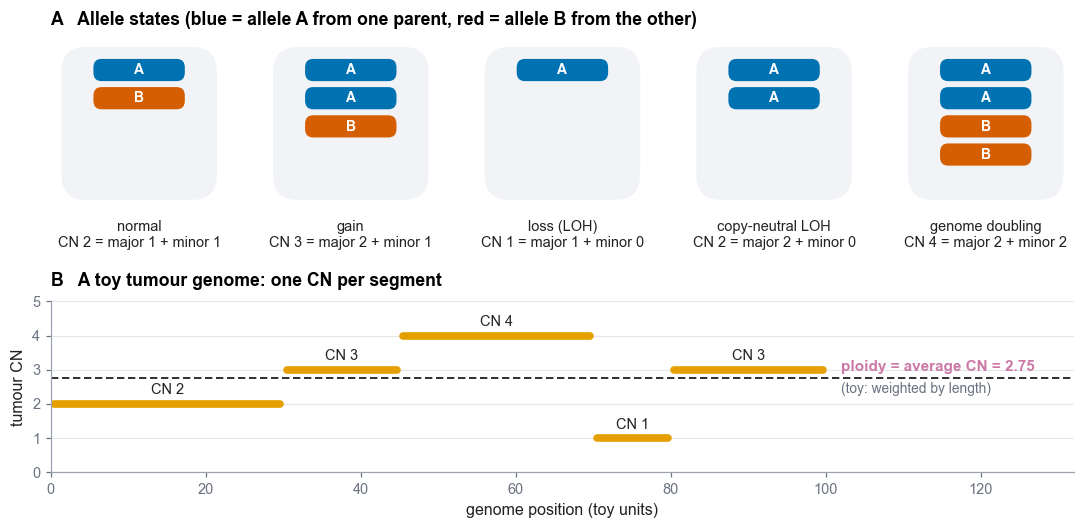

In [6]:
draw_cn_states()

**그림에서 볼 것**
- 위: 파랑(A)과 빨강(B)이 두 부모의 allele 입니다. "gain" 은 CN 3 = major 2 + minor 1, "loss" 는 CN 1 = 1 + 0 입니다.
- "copy-neutral LOH" 는 CN 이 2 로 정상과 같지만 minor 가 0 입니다. 깊이로는 안 보이고 BAF 로만 보입니다.
- "genome doubling"(WGD, 유전체 전체가 한 번에 두 배가 되는 사건)은 (2,2) 입니다. 이 상태가 B2·B3 의 "두 배 해" 문제와 이어집니다.
- 아래: 장난감 ploidy 는 구간들의 CN 을 길이로 가중 평균한 값(점선)입니다. PURPLE 은 같은 일을 BAF 점 수로 가중해 합니다.

### 4. 깊이 비와 normFactor

**한 줄 정의**: 깊이 비는 창(window, 유전체를 1 kb 씩 자른 칸)의 평균 깊이(창에 들어온 염기 수 ÷ 1,000)를 GC 보정(GC 함량 때문에 생긴 치우침을 없애는 일, 5절)한 뒤 시료 전체 수준으로 나눈 상대 깊이이고,
normFactor 는 **CN 2 인 구간이 깊이 비로 얼마에 찍히는지**를 나타내는 값입니다 [1][2].

**왜 필요한가**: COBALT 는 깊이를 유전체 전체 깊이로 나눠 깊이 비가 대략 1 근처가 되게 맞춥니다 [3].
그런데 종양의 ploidy 가 2 가 아니면 깊이 비 1.0 은 CN 2 가 아닙니다. ploidy 가 3 이면 1.0 은 CN 3 근처이고, CN 2 구간은 1 보다 낮게 찍힙니다.
그래서 "CN 2 는 깊이 비 어디인가"를 따로 찾아야 하고, 그 값이 normFactor 입니다.

**숫자로 따라가기** (purity 0.6, 같은 길이 구간 6 개의 CN 이 2, 4, 2, 4, 3, 3 → ploidy 3)

| 구간 CN | 종양 몫 0.6 × CN | 정상 몫 2 × 0.4 | DNA 합 | 깊이 비 = 합 ÷ 평균 2.6 |
|---|---|---|---|---|
| 2 | 1.2 | 0.8 | 2.0 | 0.77 |
| 3 | 1.8 | 0.8 | 2.6 | 1.00 |
| 4 | 2.4 | 0.8 | 3.2 | 1.23 |

CN 2 구간이 0.77 에 찍히므로 normFactor 는 0.77 입니다. copy 하나마다 0.23 씩(= normFactor × purity ÷ 2) 올라갑니다.

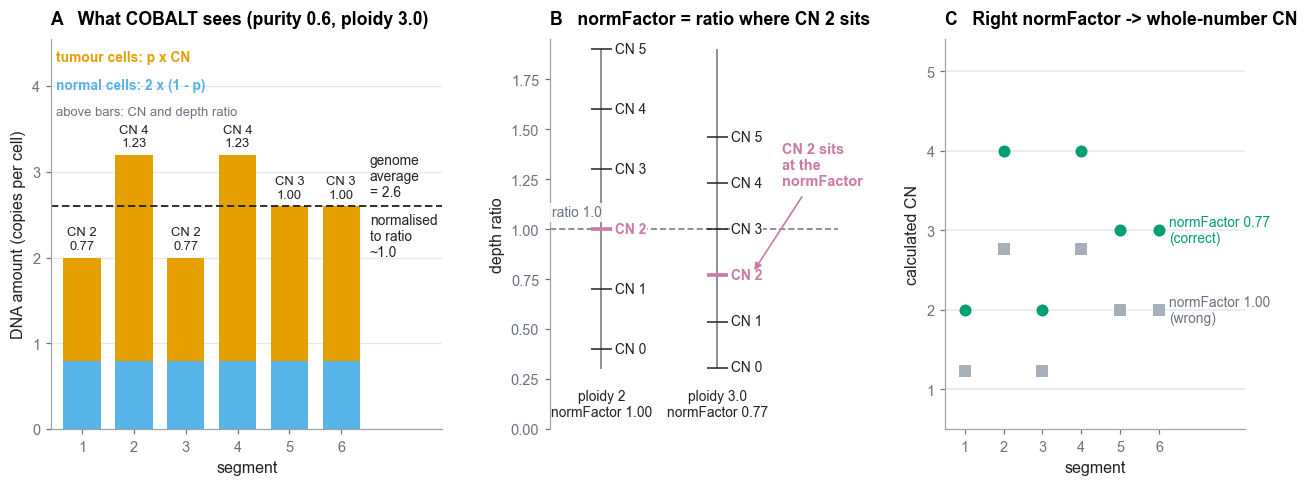

In [7]:
draw_norm_factor(p=0.6, cns=(2, 4, 2, 4, 3, 3))

**그림에서 볼 것**
- A: 구간마다 DNA 양은 정상 몫(하늘색, 늘 0.8)에 종양 몫(주황)을 더한 것입니다. 점선(평균)이 깊이 비 1 근처가 됩니다.
- B: 같은 purity 라도 ploidy 가 2 인 종양은 CN 2 가 1.00 에, ploidy 3 인 종양은 0.77 에 있습니다. 0 점과 눈금 간격이 함께 바뀝니다(copy 하나당 0.30 대 0.23).
- C: 맞는 normFactor(초록 점)로 바꾸면 모든 구간의 CN 이 정수에 떨어집니다. 틀린 값(회색 네모)을 넣으면 일부(seg 5, 6)는 우연히 정수에 떨어져도 전체가 맞지는 않습니다.
  PURPLE 은 이 "구간 전체가 정수에 잘 떨어지는가"로 purity 와 normFactor 를 고릅니다 [1].

**식과 근거** (`PurityAdjuster.java` 의 `impliedNormFactor`, `impliedAverageRatio`, `purityAdjustedCopyNumber` [2])

$$r = n_f\left(1 - p + \frac{p}{2}CN\right), \qquad n_f = \frac{2\bar r}{2 - 2p + \psi p}, \qquad CN = 2 + \frac{2(r - n_f)}{p \cdot n_f}$$

$\bar r$ 는 맞추기에 쓰는 구간들의 평균 깊이 비입니다. 이 노트북의 가짜 데이터에서는 1 로 둡니다. 아래에서 표의 숫자를 식으로 확인합니다.

**직접 바꿔 보기**: 아래 셀의 `p` 를 0.2 로 바꾸면 B 의 눈금이 촘촘해집니다. copy 하나가 깊이 비에서 차지하는 폭이 줄어드는 것, 이것이 이 노트북 질문의 첫 번째 답입니다.

In [8]:
p, cns = 0.6, np.array([2, 4, 2, 4, 3, 3])
dna = pm.relative_dna(p, cns)
nf = pm.norm_factor(p, cns.mean())
assert np.allclose(dna / dna.mean(), pm.ratio_from_cn(cns, p, nf))
assert np.allclose(pm.cn_from_ratio(dna / dna.mean(), p, nf), cns)
print(f"normFactor = {nf:.3f}, ratio step per copy = {nf * p / 2:.3f}")
# draw_norm_factor(p=0.2)

normFactor = 0.769, ratio step per copy = 0.231


### 5. GC 함량과 GC 편향: 왜 깊이가 copy 수와 상관없이 흔들리나

**한 줄 정의**: GC 함량은 DNA 한 토막에서 G 와 C 염기가 차지하는 비율입니다. **GC 편향**은 GC 함량에 따라 read 가 덜 나오거나 더 나오는 현상입니다 [7].

**왜 문제인가**: 깊이로 copy 수를 재려면 "copy 가 같으면 read 수도 같다"가 성립해야 합니다. 그런데 Illumina 데이터에서는
**GC 가 아주 높은 조각과 아주 낮은(AT 가 많은) 조각이 모두 적게 나옵니다** [7]. 라이브러리를 만들 때의 PCR 증폭이 주된 원인으로 꼽힙니다 [7][8].
GC 함량은 유전체를 따라 오르내리므로, 보정하지 않으면 copy 수가 그대로인 곳에서도 깊이가 물결칩니다.
이 물결은 copy 수 변화처럼 보여, copy 수 추정에서는 편향이 신호를 덮어 버릴 수도 있습니다 [7].

**숫자로 따라가기**

| | 창 X | 창 Y |
|---|---|---|
| GC 함량 | 0.44 (수율 가장 좋음) | 0.60 |
| 아래 장난감 곡선의 read 수율 | 1.00 | 0.28 |
| 진짜 CN | 2 | 2 |
| 보정 전 깊이 비 (둘의 평균을 1 로) | 1.56 | 0.44 |

둘 다 CN 2 인데 보정 전 깊이 비만 보면 창 Y 는 copy 를 잃은 것처럼 보입니다. 장난감 곡선은 모양만 흉내 낸 것이라 숫자 크기는 실제와 다릅니다.

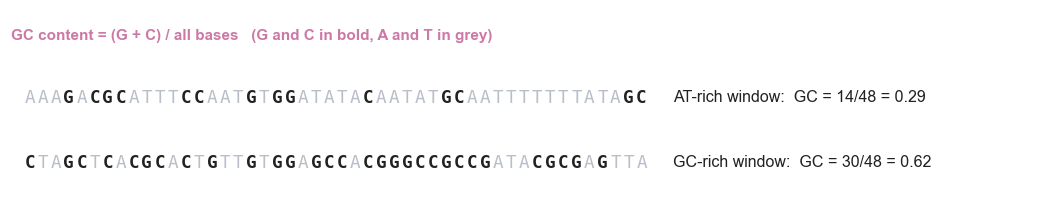

In [9]:
draw_gc_sequence()

**그림에서 볼 것**: 진한 글자가 G 와 C 이고, 옅은 회색 글자가 A 와 T 입니다. 위 줄은 GC 가 약 0.3, 아래 줄은 약 0.6 입니다. 사람 유전체에는 이런 구간이 섞여 있습니다.

이제 GC 가 깊이를 어떻게 흔드는지, COBALT 가 그것을 어떻게 고치는지 장난감 유전체로 봅니다.
3 Mb 를 COBALT 처럼 1 kb 창 3,000 개로 나누고, 진짜 CN 은 모두 2 인데 가운데 300 kb 만 CN 3 으로 둡니다(purity 0.6, 깊이 60).

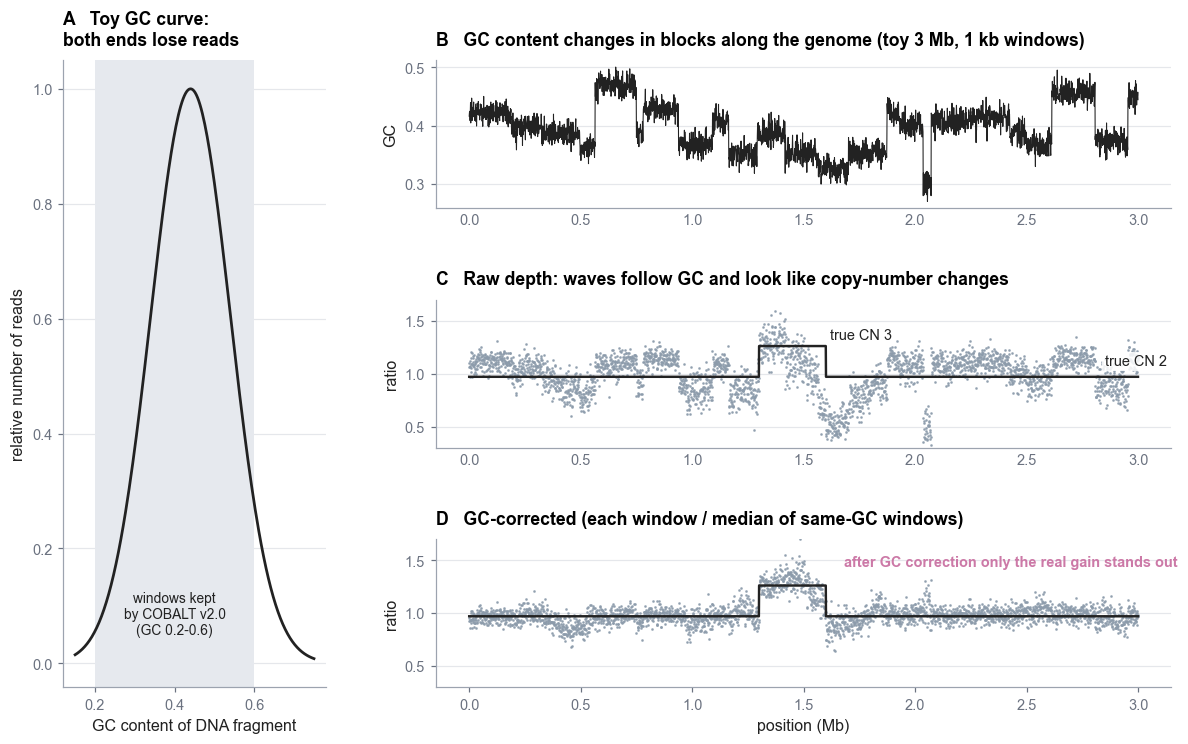

In [10]:
gc_sim = draw_gc_bias()
assert round(float(gc_yield(0.44)), 2) == 1.0 and round(float(gc_yield(0.60)), 2) == 0.28   # 숫자 표의 수율

**그림에서 볼 것**
- A: 장난감 GC 곡선입니다. 가운데 GC 에서 read 가 가장 많고, 양쪽 끝으로 갈수록 줄어듭니다(한 봉우리 모양). 실제 곡선도 이렇게 한 봉우리지만, 모양은 시료마다 다릅니다 [7].
  옅은 회색 띠는 COBALT v2.0 이 쓰는 창의 GC 범위입니다. 이 밖의 창은 아예 버립니다 [3].
- B: GC 함량이 수십~수백 kb 덩어리로 오르내립니다(장난감). 실제 PURPLE 설명서도 GC 편향이 **Mb 규모와 kb 규모** 둘 다에서 생긴다고 적습니다 [1].
- C: 보정 전 깊이 비(회청색 점)는 GC 를 따라 물결칩니다. 검은 선(진짜 CN 2 와 CN 3)과 비교하면, 물결만 보고는 어디가 진짜 gain 인지 헷갈립니다.
- D: **GC 가 같은 창끼리 묶어 그 묶음의 중앙값으로 나누면** 물결이 대부분 사라지고 진짜 gain 은 남습니다. 그래도 작은 물결이 남습니다.

**COBALT 가 하는 일** [3]
1. 정렬된 read 의 염기를 겹치는 1 kb 창에 나눠 담고, 창마다 염기 수를 1,000 으로 나눠 평균 깊이를 냅니다(매핑 품질 10 이상, 중복·보조 read 제외).
   cobalt-v1.16 부터 read 수 대신 이 평균 깊이를 씁니다(`ReadDepthAccumulator.java` [3]).
2. GC 가 너무 낮거나 높은 창(v2.0: 0.2 미만 또는 0.6 초과)과 매핑이 어려운 창(평균 mappability 0.85 미만)을 뺍니다.
3. **GC 함량이 같은 창들의 중앙값 깊이로 각 창을 나눕니다.** 그 뒤 전체 창의 중앙값/평균 비로 한 번 더 맞춥니다.
4. 정상 시료 쪽에는 10 Mb 창 단위로 한 번 더 맞춰 Mb 규모의 GC 편향을 줄입니다.

최신 COBALT 설명서는 조금 다릅니다: GC 범위가 0.24~0.67 이고, 버킷마다 구한 중앙값을 양옆 버킷과 평균해 매끄럽게 한 뒤 나눕니다 [4].
내 결과가 어느 판인지는 COBALT 버전을 보고 맞춰 읽으세요.

최신 COBALT 는 두 가지가 더 다릅니다: 창의 GC 를 참조 서열이 아니라 **그 창에 들어온 read 의 염기**로 잽니다(깊이가 아주 낮은 창만 참조 서열 값을 씁니다).
그리고 10 Mb 단위의 이배체 보정(Diploid ratios)을 정상 시료뿐 아니라 WGS 종양 시료에도 합니다 [4].

**왜 작은 물결이 남나 (이 노트북의 모형 가정)**: 위 그림에서는 read 수율이 창의 GC 가 아니라 DNA 조각의 GC 를 따르게 하고,
창 GC 로는 안 보이는 느린 흔들림(창 100 개 이동 평균)을 조각 GC 에 섞었습니다. 그래서 1 kb 창의 GC 로 고쳐도 그 흔들림이 물결로 남습니다.
조각 전체의 GC 가 읽힌 부분의 GC 보다 read 수에 더 중요하다는 것은 [7] 이 보였지만, 보정 뒤 남는 수십 kb 물결이 바로 이 때문이라는 것은 **이 모형의 가정**입니다.
보정 뒤에도 물결이 남을 수 있다는 근거로는 PURPLE 설명서의 두 문장만 듭니다: GC 편향이 **Mb 규모와 kb 규모**로 생긴다는 것(QC 절)과, 다듬기 단계에서 **남은 GC 잡음**을 따로 다룬다는 것(`min_diploid_tumor_ratio_count`) [1].

**깊게 읽으면 남은 물결이 줄어드나?** 같은 유전체를 깊이 30 과 120 으로 읽고, 보정 뒤 남은 오차를 "느린 물결"(40 kb 평균)과 "창마다의 자잘한 흔들림"으로 나눠 봅니다.

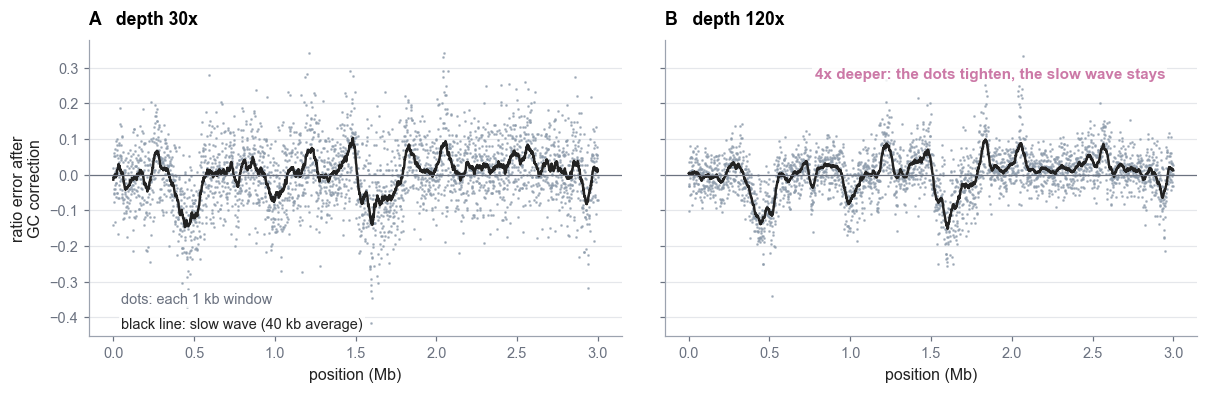

,depth,total_sd,slow_wave_sd,fast_speckle_sd
0,30,0.094,0.047,0.081
1,120,0.067,0.045,0.049


In [11]:
wave_table = draw_depth_vs_wave()
wave_table

In [12]:
w = wave_table.set_index("depth")
assert w.loc[120, "fast_speckle_sd"] < 0.7 * w.loc[30, "fast_speckle_sd"]     # 자잘한 흔들림은 깊이로 준다
assert abs(w.loc[120, "slow_wave_sd"] / w.loc[30, "slow_wave_sd"] - 1) < 0.35  # 느린 물결은 거의 그대로

**그림에서 볼 것**
- 회청색 점(창마다의 오차)은 깊이 120 에서 좁아집니다. read 수가 4 배면 그중 세기 잡음 부분은 절반이 됩니다($1/\sqrt{4}$).
- 검은 선(느린 물결)은 두 깊이에서 거의 같습니다. 이 모형에서 느린 물결은 read 를 몇 개 뽑았느냐와 상관없는 숨은 GC 흔들림(모형 가정)에서 오기 때문입니다.

이것이 이 노트북과 B3 에서 말하는 **계통 잡음**입니다. `purple_mini.simulate` 는 이 남은 물결을 이웃끼리 닮은 잡음(`sys_sd`, `sys_corr`)으로 흉내 냅니다.
표의 숫자는 이 노트북의 시뮬레이션 결과입니다.

**직접 바꿔 보기**: `simulate_gc_depth(hidden_sd=0.0)` 처럼 조각 GC 의 숨은 흔들림을 없애면 보정 뒤 물결이 거의 사라집니다. 남은 물결의 원인이 무엇인지 확인해 보세요.

### 6. 이형접합 SNP 와 BAF, 그리고 접힌 BAF

**한 줄 정의**
- **이형접합 SNP**: 두 부모에게서 서로 다른 염기를 받은 자리입니다(예: 한쪽 A, 다른 쪽 G).
- **BAF**(B-allele frequency): 그 자리를 덮는 read 가운데 B allele(여기서는 G)을 가진 read 의 비율입니다.
- **접힌 BAF**: $0.5 + |BAF - 0.5|$. 어느 allele 이 major 쪽인지 모르므로 0.5 위로 접어서 씁니다 [2].

**왜 필요한가**: 깊이 비는 총 CN 만 알려 줍니다. 두 allele 의 균형이 깨졌는지(LOH, gain 의 한쪽 쏠림)는 이형접합 자리의 read 비율로만 보입니다.

**AMBER 가 하는 일** [9]: 사람들 사이에 흔한 SNP 자리 목록(gnomAD 에서 인구 빈도 0.05~0.95 인 자리, 약 630 만 곳)을 받아,
혈액에서 allele 비율이 0.4~0.65 이고 깊이가 중앙값의 0.5~1.5 배인 자리만 이형접합으로 고릅니다. 그 자리들에서 종양 시료의 BAF 를 잽니다.

**숫자로 따라가기** (purity 0.6, 한 copy 를 잃은 LOH 구간: major 1, minor 0)

| | 남은 allele A 쪽 DNA | 잃은 allele G 쪽 DNA | 합 |
|---|---|---|---|
| 종양 세포 몫 | 0.6 × 1 = 0.6 | 0.6 × 0 = 0 | 0.6 |
| 정상 세포 몫 | 0.4 × 1 = 0.4 | 0.4 × 1 = 0.4 | 0.8 |
| 합 | 1.0 | 0.4 | 1.4 |

A 쪽 비율 = 1.0 / 1.4 = 0.71. read 20 개라면 A 가 약 14 개, G 가 약 6 개입니다. G 의 BAF 0.30 을 접으면 0.70 입니다.

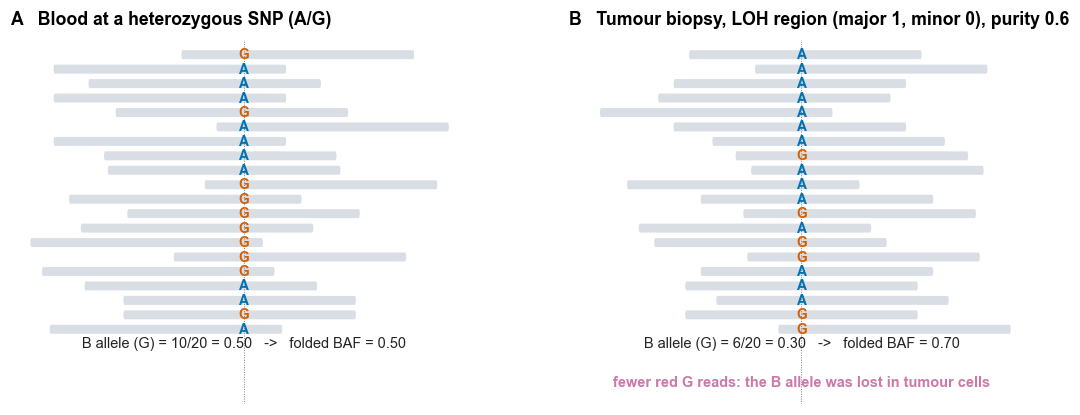

In [13]:
draw_snp_pileup(p=0.6)
assert np.isclose(pm.expected_baf(0.6, 1, 0), 1 / 1.4)

**그림에서 볼 것**
- 왼쪽(혈액): 이형접합 자리라 A 와 G 가 반씩입니다. BAF 0.5.
- 오른쪽(종양, LOH): 정상 세포 몫 때문에 G 가 완전히 사라지지 않고 6 개 남습니다. purity 가 낮을수록 G 가 더 많이 남아 0.5 에 가까워집니다.

**식과 근거**: 종양 몫과 정상 몫을 더하면 $BAF_{major} = \dfrac{p \cdot major + (1-p)}{p \cdot CN + 2(1-p)}$ 입니다.
PURPLE 은 같은 식을 거꾸로 풀어 관찰 BAF 에서 종양 BAF 를 되돌립니다(`PurityAdjuster.purityAdjustedFrequency` [2]).

이제 한 구간 안의 SNP 자리 수천 개를 모으면 어떻게 보이는지, 그리고 왜 접는지 봅니다.

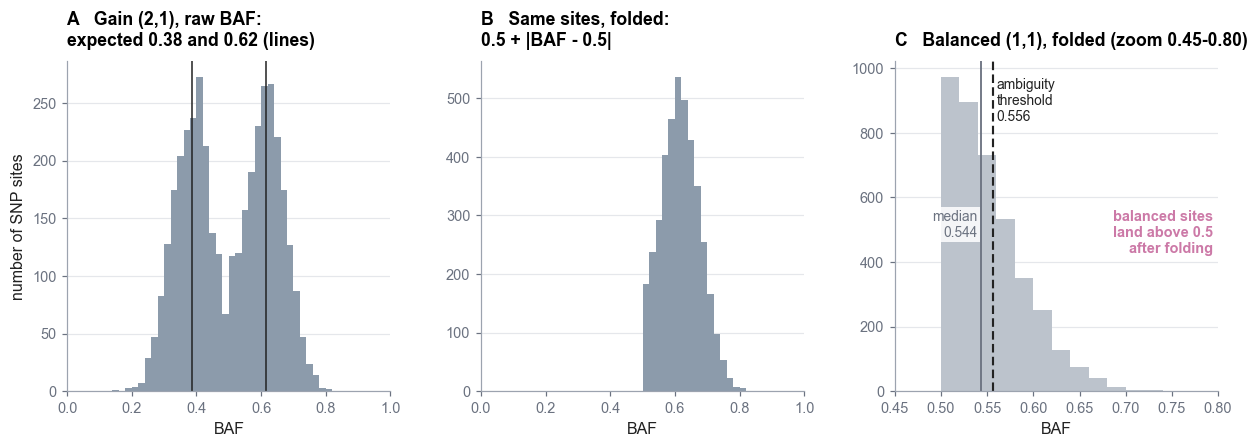

balanced sites above the threshold line: 37.6%


In [14]:
above = draw_folding(p=0.6, depth=60)
print(f"balanced sites above the threshold line: {above:.1%}")
assert 0.3 < above < 0.5

**그림에서 볼 것**
- A: gain (2,1) 구간입니다. 어떤 자리에서는 B allele 이 major 쪽, 어떤 자리에서는 minor 쪽에 있어 기대값 0.38 과 0.62(검은 세로선) 근처에 봉우리가 두 개 생깁니다. read 수가 정수라 막대는 선에서 조금 비켜 쌓입니다(왼쪽 봉우리 막대는 0.40 칸).
- B: 접으면(0.5 위로 뒤집으면) 한 봉우리 0.62 가 됩니다. AMBER 결과 파일의 `tumorModifiedBAF` 가 이 값입니다 [2].
- C: 균형 구간(1,1)도 read 를 뽑는 우연 때문에 0.5 위아래로 흩어지는데, 접으면 **모두 0.5 위로** 올라갑니다. 중앙값이 0.5 가 아니라 0.54 근처입니다(접기 치우침). C 는 0.45~0.80 만 확대해, 중앙값(회색 선)과 기준선(검은 점선)이 떨어져 보이게 했습니다.
  검은 점선은 PURPLE 의 **모호 판정 기준선**입니다. 접기 **전** BAF 분포(균형 자리의 read 비율)의 80 백분위를 깊이 $D/2$~$1.5D$ 에 걸쳐 평균한 값입니다(`ExpectedBAF.java` [2]).
  접은 분포로는 대략 60 백분위라서, 이 그림에서도 균형 자리의 약 40% 가 선보다 높습니다(아래 출력). 그러니 "균형 구간의 위쪽 경계"는 아닙니다.
  PURPLE 은 구간의 관찰 BAF 가 이 선 이하이면 BAF 를 0.5 로 볼 때와 관찰값으로 볼 때의 벌점을 비교해 작은 쪽을 고릅니다(`RegionFitCalculator.bafToMinimiseDeviation` [2]).

**직접 바꿔 보기**: `draw_folding(depth=200)` 으로 깊이를 올려 보세요. C 의 봉우리와 검은 점선이 0.5 쪽으로 내려옵니다.

## 7. purity 가 낮으면 두 신호가 얼마나 작아지나

이제 개념은 다 나왔습니다. 남은 절은 같은 식을 purity 를 바꿔 가며 다시 보는 것입니다.

### 7-1. 깊이 비: copy 하나당 $n_f \cdot p/2$

4절의 식에서 copy 하나당 깊이 비 변화는 기울기 $n_f p/2$ 입니다. ploidy 가 2 근처면 $n_f \approx 1$ 이므로 대략 $p/2$ 입니다.

| purity | copy 하나당 깊이 비 변화 |
|---|---|
| 0.8 | 약 0.40 |
| 0.2 | 약 0.10 |
| 0.1 | 약 0.05 |

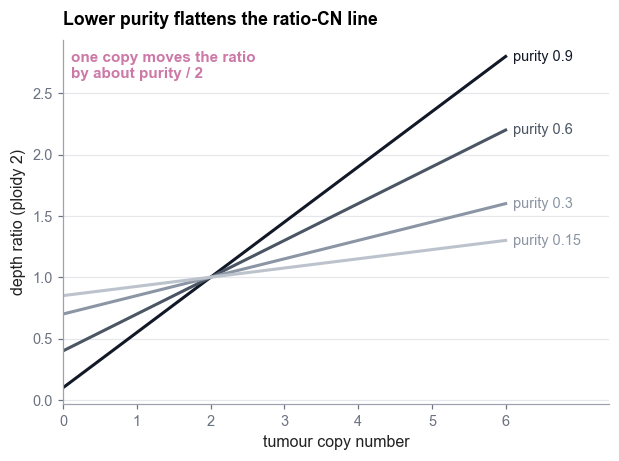

In [15]:
draw_ratio_lines()

**그림에서 볼 것**: purity 가 낮을수록 선이 눕습니다. 누운 선에서는 CN 이 하나 바뀌어도 깊이 비가 조금밖에 안 움직입니다.

### 7-2. 거꾸로 풀면 같은 잡음이 $1/p$ 배로 커진다

**한 줄 정의**: 깊이 비 잡음 $\delta r$ 이 CN 으로 옮겨 가면 $\delta CN = \dfrac{2}{p \cdot n_f}\,\delta r$ 가 됩니다(4절 CN 식을 미분한 것).

**숫자로 따라가기** (ploidy 2, 깊이 비 잡음 3%)

| purity | CN 흔들림 |
|---|---|
| 0.8 | 2/0.8 × 0.03 ≈ 0.08 |
| 0.2 | 2/0.2 × 0.03 = 0.30 |
| 0.1 | 2/0.1 × 0.03 = 0.60 |

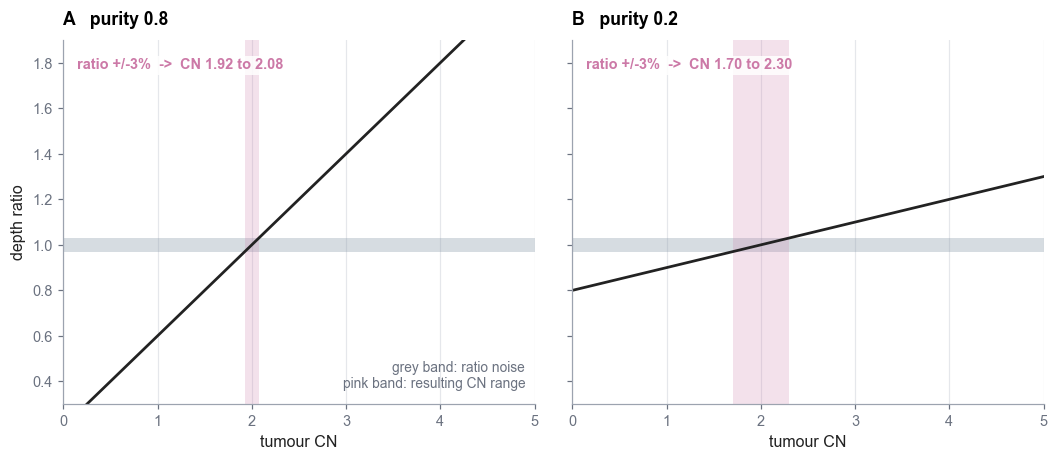

In [16]:
draw_noise_to_cn(noise=0.03)

**그림에서 볼 것**: 회청색 가로 띠(깊이 비 ±3%)는 두 그림에서 높이가 거의 같습니다. 그런데 그 띠가 누운 선(purity 0.2)과 만나는 CN 범위(분홍 세로 띠)는 훨씬 넓습니다.
잡음은 그대로인데 선이 누워서 CN 이 크게 흔들립니다. **이것이 질문에 대한 첫 번째 답입니다.**

In [17]:
noise = 0.03
rows = []
for p in [0.9, 0.6, 0.4, 0.3, 0.2, 0.1]:
    nf = pm.norm_factor(p, 2.0)
    rows.append(dict(purity=p, ratio_step_per_copy=round(nf * p / 2, 3),
                     CN_wobble_from_3pct_noise=round(2 / (p * nf) * noise, 2)))
pd.DataFrame(rows)

,purity,ratio_step_per_copy,CN_wobble_from_3pct_noise
0,0.9,0.45,0.07
1,0.6,0.30,0.10
2,0.4,0.20,0.15
3,0.3,0.15,0.20
4,0.2,0.10,0.30
5,0.1,0.05,0.60


### 7-3. BAF: 모든 상태가 0.5 로 몰린다

6절의 BAF 식에 purity 를 바꿔 넣습니다. LOH (1,0) 은 $BAF = 1/(2-p)$ 라서 purity 0.8 이면 0.83, 0.1 이면 0.53 입니다.
(1,1) 과 (2,2) 는 purity 와 상관없이 0.5 라서 한 선으로 겹칩니다.

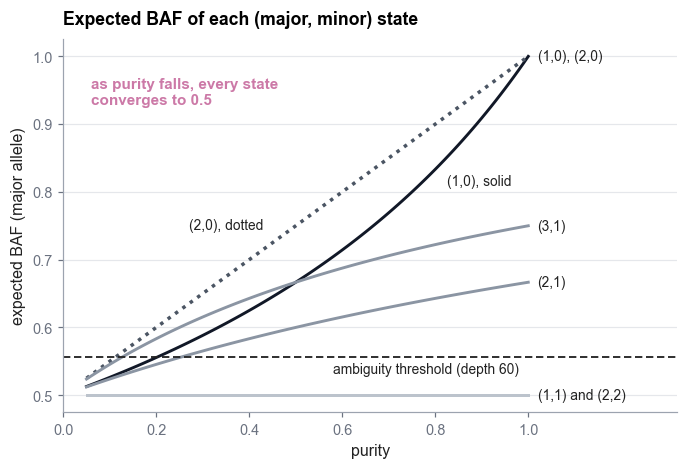

In [18]:
purity = np.linspace(0.05, 1, 96)   # 아래 표에서도 씀
draw_baf_convergence()

**그림에서 볼 것**: 왼쪽으로 갈수록(purity 가 낮을수록) 모든 선이 0.5 로 모입니다. 선이 검은 점선(6절 그림 C 의 모호 판정 기준선) 아래로 내려가면 그 상태는 균형 구간과 헷갈리기 쉬워집니다.
이때 PURPLE 은 "BAF 0.5 로 볼 때"와 "관찰값으로 볼 때" 가운데 벌점이 작은 쪽을 고르므로 [2], 기준선 아래라고 바로 구별을 포기하는 것은 아닙니다.

아래 표는 각 상태의 기대 BAF 가 기준선 위로 올라오는 가장 낮은 purity 입니다.

In [19]:
rows = []
for depth in [30, 60, 120]:
    thr = pm.ambiguous_baf(depth)
    row = {"depth": depth, "threshold": round(thr, 3)}
    for M, m in [(1, 0), (2, 1), (3, 1)]:
        b = pm.expected_baf(purity, M, m)
        row[f"min purity above threshold ({M},{m})"] = round(purity[np.argmax(b > thr)], 2)
    rows.append(row)
pd.DataFrame(rows)

,depth,threshold,"min purity above threshold (1,0)","min purity above threshold (2,1)","min purity above threshold (3,1)"
0,30,0.581,0.28,0.39,0.20
1,60,0.556,0.21,0.26,0.13
2,120,0.540,0.15,0.18,0.09


In [20]:
p, M, m = 0.45, 3, 1
obs = pm.expected_baf(p, M, m)
tumour_baf = pm.baf_from_observed(obs, p, M + m)
assert np.isclose(tumour_baf, M / (M + m))
print(f"observed {obs:.3f} -> tumour BAF {float(tumour_baf):.3f} -> major {float(tumour_baf) * (M + m):.2f}, minor {(1 - float(tumour_baf)) * (M + m):.2f}")

observed 0.655 -> tumour BAF 0.750 -> major 3.00, minor 1.00


### 7-4. NRPCC: 종양 copy 하나가 받는 read 수

**한 줄 정의**: NRPCC(number of reads per chromosome copy)는 종양 염색체 copy 하나에서 나온 read 수입니다. purity, ploidy, 깊이를 한 숫자로 묶은 것입니다 [10].

**왜 필요한가**: 깊이 60 이라도 purity 가 낮으면 그 read 대부분이 정상 세포에서 옵니다. 종양을 보는 데 실제로 쓰이는 read 는 훨씬 적습니다.
PCAWG 의 이질성 분석은 이 값이 10 이상인 종양만 subclone(종양 세포 가운데 일부만 가진 변이를 공유하는 세포 무리) 분석에 썼습니다 [10].

**식과 근거**: $NRPCC = \dfrac{D \cdot p}{p\psi + 2(1-p)}$ ($D$ 평균 깊이, 정상 ploidy 2) [10].

**숫자로 따라가기** (깊이 60, ploidy 2 종양의 CN 2 자리)

| purity | 종양 copy 하나당 | 정상 copy 하나당 |
|---|---|---|
| 0.8 | 60 × 0.8 / 2 = 24 | 60 × 0.2 / 2 = 6 |
| 0.2 | 60 × 0.2 / 2 = 6 | 60 × 0.8 / 2 = 24 |

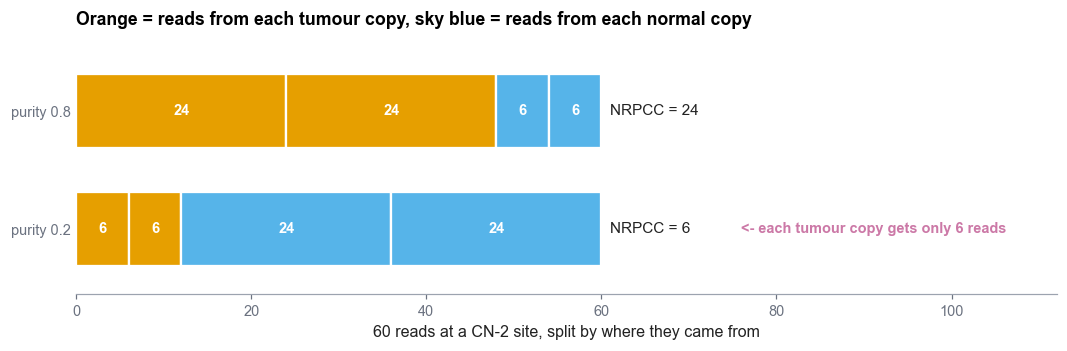

In [21]:
draw_nrpcc(depth=60, purities=(0.8, 0.2))
assert np.isclose(pm.nrpcc(60, 0.8, 2), 24) and np.isclose(pm.nrpcc(60, 0.2, 2), 6)

**그림에서 볼 것**: 막대 길이(read 60 개)는 같지만, purity 0.2 에서는 주황(종양 copy) 칸이 6 개짜리로 줄고 하늘색(정상 copy) 칸이 24 개로 커집니다.

아래 표처럼 깊이를 두 배로 해도 NRPCC 는 두 배밖에 늘지 않습니다. purity 를 0.1 에서 0.4 로 올리는 것이 훨씬 큽니다.
다만 NRPCC 는 **세기 잡음**만 대변합니다. 5절의 GC 물결 같은 계통 잡음은 깊이와 상관없으므로 NRPCC 로는 설명되지 않습니다.

In [22]:
rows = []
for depth in [30, 60, 120]:
    for p in [0.8, 0.4, 0.2, 0.1]:
        rows.append(dict(depth=depth, purity=p, NRPCC=round(pm.nrpcc(depth, p, 2.0), 1)))
pd.DataFrame(rows).pivot(index="purity", columns="depth", values="NRPCC").sort_index(ascending=False)

depth,30,60,120
purity,,,
0.8,12.0,24.0,48.0
0.4,6.0,12.0,24.0
0.2,3.0,6.0,12.0
0.1,1.5,3.0,6.0


## 8. 가짜 종양 데이터 만들기

`purple_mini.py` 의 두 함수로 B2~B4 에서 쓸 가짜 데이터를 만듭니다.

- `random_profile(seed)`: 22 개 상염색체(hg38 길이)를 무작위로 끊어 구간마다 (major, minor) 를 붙인 **진짜 CN 지도**입니다. 끊긴 자리는 모두 SV(구조 변이)가 받쳐 준다고 둡니다.
- `simulate(profile, purity, depth, ...)`: 그 종양을 그 purity 로 읽었을 때 COBALT·AMBER 가 낼 법한 값을 만듭니다.
  - 깊이 비: 100 kb 칸마다 하나(1 kb 창 100 개를 합친 것으로 봅니다). 세기 잡음(Poisson), 이웃끼리 닮은 계통 잡음(`sys_sd`, 5절의 남은 GC 물결 대신), 칸마다 독립인 잡음(`white_sd`).
  - BAF: 칸마다 이형접합 SNP 를 평균 30 개 두고, 자리마다 read 수와 B allele read 수를 뽑아 접습니다.

실제 도구와 다른 점: 성염색체·동원체가 없고, GC 편향은 이미 보정되고 남은 물결만 넣었습니다. 깊이 비는 종양 시료의 GC 보정 비 하나만 만듭니다.
PURPLE 도 맞추기에는 종양 쪽 비(`tumorGCRatio`)만 쓰고, 정상 시료의 비는 germline 상태 판정과 정상 기준 CN(`refNormalisedCopyNumber`)에만 씁니다(`ObservedRegionFactory.java` [2]).
이 가짜 데이터는 정상 시료가 어디나 이배체라고 보고 정상 쪽 비를 따로 만들지 않았습니다.

In [23]:
prof = pm.random_profile(seed=1)
print("segments:", len(prof), " true ploidy:", round(pm.profile_ploidy(prof), 2))
prof.head()

segments: 98  true ploidy: 2.22


,chromosome,start_bin,end_bin,major,minor
0,1,0,686,1,1
1,1,686,1052,2,1
2,1,1052,2039,1,0
3,1,2039,2137,1,1
4,1,2137,2480,2,1


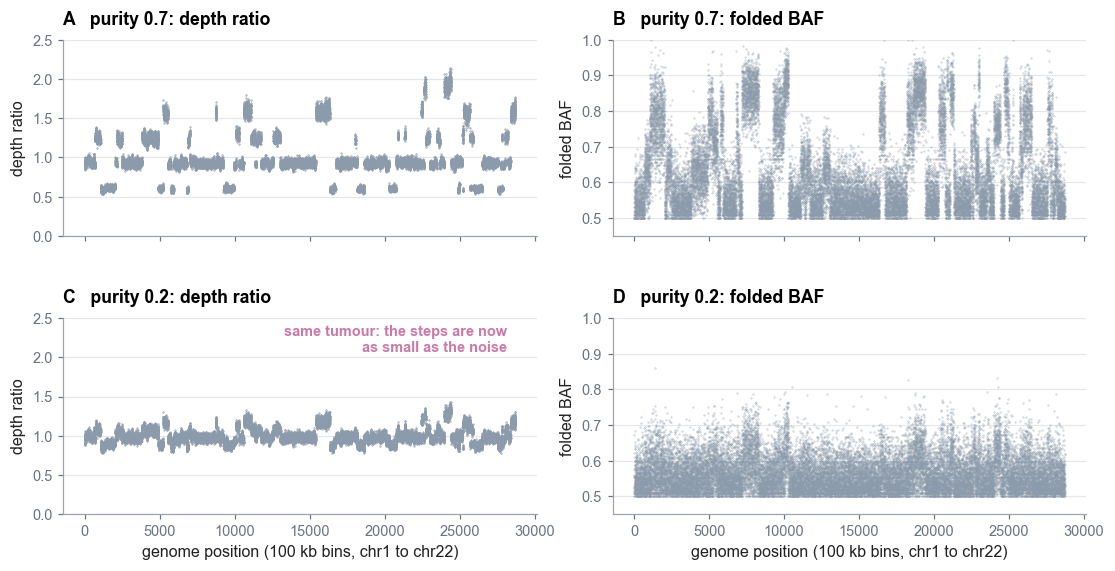

In [24]:
sims = {p: pm.simulate(prof, p, depth=60, seed=0) for p in [0.7, 0.2]}
draw_sim_two_purities(sims)

**그림에서 볼 것**: 위(purity 0.7)는 깊이 비와 BAF 모두 계단이 또렷합니다. 아래(purity 0.2)는 **같은 종양**인데 계단 높이가 잡음과 비슷해졌습니다.
CN 지도는 그대로인데 보이는 신호만 줄었습니다.

마지막으로 만든 데이터가 식과 맞는지 확인합니다.

In [25]:
bins, bafs = sims[0.7]
assert abs(bins.ratio.mean() - 1) < 0.02
nf = pm.norm_factor(0.7, pm.profile_ploidy(prof))
pred = pm.ratio_from_cn(bins.true_cn, 0.7, nf)
resid = bins.ratio / pred - 1
print(f"bin-level ratio noise (SD of relative residual): {resid.std():.3f}")
assert abs(resid.mean()) < 0.02

bin-level ratio noise (SD of relative residual): 0.037


## 연습 문제

1. purity 0.4, ploidy 2 인 종양에서 CN 3 인 자리의 깊이 비는 얼마입니까?
2. ploidy 2 일 때 copy 하나당 깊이 비 변화가 0.03 과 같아지는 purity 는 얼마입니까?
3. 깊이 60, purity 0.25, ploidy 2 의 NRPCC 는 얼마입니까?
4. major 2, minor 0 자리의 BAF 를 purity 0.3 에서 구하세요.
5. 깊이를 4 배로 올리면 5절의 "자잘한 흔들림"과 "느린 물결"은 각각 어떻게 됩니까?

<details><summary>정답 보기</summary>

1. $n_f = 2/(2 - 0.8 + 0.8) = 1$, $r = 1 \times (1 - 0.4 + 0.2 \times 3) = 1.2$.
2. $n_f = 1$ 이므로 $p/2 = 0.03$, 즉 purity 0.06. PURPLE 이 맞추는 가장 낮은 purity(0.08 [1]) 아래입니다.
3. $60 \times 0.25 / (0.5 + 1.5) = 7.5$.
4. $(0.3 \times 2 + 0.7) / (0.3 \times 2 + 1.4) = 1.3 / 2.0 = 0.65$.
5. 자잘한 흔들림 가운데 세기 잡음 부분은 $1/\sqrt 4$ = 절반이 되지만, 다른 빠른 흔들림(GC 버킷 중앙값의 흔들림 등)이 섞여 있어 표의 자잘한 흔들림 전체는 약 0.6 배(0.08 → 0.05)로 줄었습니다. 느린 물결(계통 잡음)은 거의 그대로입니다.

</details>

In [26]:
assert np.isclose(pm.ratio_from_cn(3, 0.4, pm.norm_factor(0.4, 2)), 1.2)
assert np.isclose(pm.nrpcc(60, 0.25, 2), 7.5)
assert np.isclose(pm.expected_baf(0.3, 2, 0), 0.65)

## 정리

- 깊이 비는 $n_f(1 - p + p \cdot CN/2)$ 입니다. normFactor $n_f$ 는 CN 2 가 찍히는 깊이 비이고, copy 하나에 $n_f p/2$ 만큼 움직입니다.
- CN 은 $2 + 2(r - n_f)/(p n_f)$ 로 되돌립니다. 깊이 비 잡음은 **$1/p$ 배로 커져** CN 에 들어갑니다.
- GC 편향은 copy 수와 상관없이 깊이를 물결치게 합니다. COBALT 가 대부분 고치지만, 남은 물결은 깊게 읽어도 줄지 않는 **계통 잡음**이 됩니다(이 노트북의 모형에서 확인).
- BAF 는 purity 가 낮을수록 0.5 로 몰리고, 모호 판정 기준선 근처로 내려가면 major·minor 를 가르기 어려워집니다.
- NRPCC 는 purity 와 깊이를 묶은 "종양 copy 하나당 read 수"입니다. 세기 잡음의 크기를 알려 주지만 계통 잡음은 설명하지 못합니다.

다음 노트북(B2)에서는 purity 와 ploidy 를 **모르는** 상태에서 PURPLE 이 이 둘을 어떻게 찾는지 봅니다.

## 출처

모두 2026-11-13 에 직접 열어 확인했습니다.

1. **PURPLE README**, hmftools 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md
   — 이 노트북에서: purity·ploidy 정의(Output 의 purity file 열 설명), 시료 두 개와 입력(Input), 정수 CN 으로 맞춘다는 생각(Algorithm 3), purity 범위 0.08~1, GC 편향이 Mb·kb 규모로 생겨 CN noise 경고로 이어진다는 문장(9. QC Status), 남은 GC 잡음을 다듬기에서 다룬다는 설명(`min_diploid_tumor_ratio_count`).
2. **PURPLE·hmf-common 소스**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/tree/purple-v4.1
   — `purple/.../fitting/PurityAdjuster.java`(normFactor, 깊이 비 ↔ CN, BAF 되돌리기), `purple/.../fitting/FittedPurityFactory.java`(출력 ploidy = BAF 점 수 가중 평균 CN), `purple/.../segment/ExpectedBAF.java`(모호 판정 기준선: 접기 전 80 백분위, 깊이 D/2~1.5D 평균), `purple/.../fitting/RegionFitCalculator.java`(`bafToMinimiseDeviation`), `hmf-common/.../amber/AmberBAF.java`(`tumorModifiedBAF = 0.5 + |BAF − 0.5|`), `purple/.../region/ObservedRegionFactory.java`(맞추기에 쓰는 비는 종양 GC 비 `tumorGCRatio`, 정상 GC 비는 germline 상태 판정에 씀; 2026-11-14 확인).
3. **COBALT README**, 태그 `cobalt-v2.0`. https://github.com/hartwigmedical/hmftools/blob/cobalt-v2.0/cobalt/README.md
   — 1 kb 창, 창 깊이 = 창에 들어온 염기 수 ÷ 1,000(`cobalt/.../count/ReadDepthAccumulator.java` L86, 2026-11-14 확인; cobalt-v1.16 릴리스 노트 "use mean read depths instead of read counts", https://github.com/hartwigmedical/hmftools/releases/tag/cobalt-v1.16), read 거르기, GC 0.2~0.6·mappability 0.85 거르기, 같은 GC 창의 중앙값으로 나누기, median/mean 보정, 정상 시료의 Mb 규모 보정.
4. **COBALT README**, 최신판(master, 2026-11-13 확인). https://github.com/hartwigmedical/hmftools/blob/master/cobalt/README.md
   — GC 범위 0.24~0.67, 창 GC 를 read 염기로 잼(깊이가 아주 낮은 창만 참조값), 버킷 중앙값을 양옆 버킷과 평균하는 단계, 이배체 보정(Diploid ratios)을 WGS 종양에도 적용, targeted 모드에서만 평균을 정확히 1 로 맞추는 단계(Unity).
5. **Priestley P, et al.** (2019) Pan-cancer whole-genome analyses of metastatic solid tumours. *Nature* 575:210–216. https://doi.org/10.1038/s41586-019-1689-y
   — 종양 중앙값 106x·혈액 중앙값 38x 짝 시료(초록), PURPLE 이 BAF·깊이·SV 를 합쳐 purity 와 CN 을 정한다는 Methods 설명.
6. **Van Loo P, et al.** (2010) Allele-specific copy number analysis of tumors. *PNAS* 107:16910–16915. https://doi.org/10.1073/pnas.1009843107
   — 정상 세포 섞임과 ploidy 를 함께 추정하며 allele 별 CN 을 매기는 접근(ASCAT).
7. **Benjamini Y, Speed TP** (2012) Summarizing and correcting the GC content bias in high-throughput sequencing. *Nucleic Acids Res* 40:e72. https://doi.org/10.1093/nar/gks001
   — GC 편향의 정의, 한 봉우리 모양(GC 많은 조각과 AT 많은 조각 모두 적게 나옴), copy 수 추정 신호를 덮을 수 있음, 시료마다 다름, 읽힌 부분보다 조각 전체의 GC 가 더 중요함, PCR 이 주원인이라는 가설.
   (보정 뒤 남는 수십 kb 물결의 원인은 이 논문의 주장이 아니라 이 노트북의 모형 가정입니다.)
8. **Aird D, et al.** (2011) Analyzing and minimizing PCR amplification bias in Illumina sequencing libraries. *Genome Biol* 12:R18. https://doi.org/10.1186/gb-2011-12-2-r18
   — 염기 조성이 극단적인 자리가 적게 읽힘, 라이브러리 PCR 이 주된 원인.
9. **AMBER README**, 태그 `amber-v4.1`. https://github.com/hartwigmedical/hmftools/blob/amber-v4.1/amber/README.md
   — gnomAD 기반 SNP 자리 목록(인구 빈도 0.05~0.95, 약 630 만 곳), 이형접합 판정(혈액 allele 비율 0.4~0.65, 깊이 0.5~1.5 배), 종양 BAF 측정.
10. **Dentro SC, et al.** (2021) Characterizing genetic intra-tumor heterogeneity across 2,658 human cancer genomes. *Cell* 184:2239–2254. https://doi.org/10.1016/j.cell.2021.03.009
    — NRPCC 정의와 식(STAR Methods "Power analysis and sample filtering"), NRPCC ≥ 10 기준.

이 노트북의 장난감 GC 곡선, GC 덩어리 모양, 깊이별 물결 표는 **이 노트북의 시뮬레이션**이며 실제 데이터의 크기를 뜻하지 않습니다.